In [13]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Purpose:
Connects Google Colab to Google Drive to access the dataset and save output files

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, learning_curve, validation_curve, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# Load Data
file_path = '/content/drive/MyDrive/CSC4110_G07/data/weatherAUS.csv'
df = pd.read_csv(file_path)

# Clean
df['Date'] = pd.to_datetime(df['Date'])
df = df.dropna(subset=['RainTomorrow'])
df = df.drop(columns=['Evaporation', 'Sunshine', 'Cloud9am', 'Cloud3pm', 'RISK_MM'], errors='ignore')
df['RainToday'] = df['RainToday'].map({'No': 0, 'Yes': 1})
df['RainTomorrow'] = df['RainTomorrow'].map({'No': 0, 'Yes': 1})

# CRITICAL: Sort by Date for TimeSeriesSplit
df = df.sort_values('Date')

# Split by Time
train_mask = df['Date'] < '2015-01-01'
test_mask = df['Date'] >= '2015-01-01'

features = [col for col in df.columns if col not in ['RainTomorrow', 'Date']]
X = df[features]
y = df['RainTomorrow']

X_train = X[train_mask]
y_train = y[train_mask]
X_test = X[test_mask]
y_test = y[test_mask]

print(f"Training set: {X_train.shape}, Test set: {X_test.shape}")

Training set: (98988, 17), Test set: (43205, 17)


Purpose:
This cell loads, cleans, and prepares the dataset for the evaluation pipeline.

Import Libraries: Loads all required tools for data handling, pipelines, and modeling.

Load Data: Reads the raw weatherAUS.csv file from Google Drive.

Clean Data:

Drops columns with >35% missing values (Evaporation, Sunshine, Cloud9am, Cloud3pm).

Drops rows with no RainTomorrow target.

Maps Yes/No targets to 1/0.

Sort by Date: Crucial step. Sorts the dataset chronologically so the TimeSeriesSplit knows which data is "past" and which is "future."

Time Split: Splits the data into Training (< 2015) and Testing (>= 2015) sets.

In [ ]:
# Identify numeric and categorical columns
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object']).columns

# 1. Build the preprocessing pipeline
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)])

# 2. Combine with model into one Pipeline
pipe = Pipeline(steps=[('preprocessor', preprocessor),
                       ('classifier', RandomForestClassifier(random_state=42, n_jobs=-1))])

# 3. Cross-Validation using TimeSeriesSplit
tscv = TimeSeriesSplit(n_splits=5)
cv_scores = cross_val_score(pipe, X_train, y_train, cv=tscv, scoring='f1')

print(f"CV Scores: {cv_scores}")
print(f"Mean CV F1: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

CV Scores: [0.57006107 0.60525556 0.57855791 0.60943621 0.56473134]
Mean CV F1: 0.5856 (+/- 0.0183)


This cell builds a complete machine learning pipeline and evaluates it using Time-Series Cross-Validation.

Preprocessing Pipeline:

Numeric: Fills missing values with the median and applies StandardScaler to normalise the numbers.

Categorical: Fills missing values with the most frequent value and applies OneHotEncoder to convert text to numbers.

Combine Pipeline: Combines the preprocessing steps and the RandomForestClassifier into one single pipe object to prevent data leakage.

Time-Series Cross-Validation: Uses TimeSeriesSplit with 5 folds. This ensures the model always trains on past data and validates on future data, simulating real-world forecasting.

Output: Prints the F1 score for each of the 5 folds and calculates the mean F1 score

In [ ]:
# Hyperparameter grid
grid = {
    'classifier__n_estimators': [50, 100],
    'classifier__max_depth': [5, 10, None]
}

# Grid Search with TimeSeriesSplit
grid_search = GridSearchCV(pipe, grid, cv=tscv, scoring='f1', n_jobs=-1)
grid_search.fit(X_train, y_train)

print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best CV Score: {grid_search.best_score_:.4f}")

# Evaluate on test set once at the end
test_score = grid_search.score(X_test, y_test)
print(f"Test Score (F1): {test_score:.4f}")

Best Parameters: {'classifier__max_depth': None, 'classifier__n_estimators': 100}
Best CV Score: 0.5856
Test Score (F1): 0.5733


This cell performs Hyperparameter Tuning using Grid Search to find the best Random Forest settings.

Parameter Grid: Defines a grid of options to test, including the number of trees (n_estimators) and the maximum depth (max_depth).

Grid Search: Automatically trains and evaluates the pipeline using every combination in the grid.

Time-Series Validation: Uses the TimeSeriesSplit (tscv) to ensure the tuning process respects the chronological order of the data (no peeking into the future).

Evaluation: Prints the best parameters found and the best cross-validation score. Finally, it evaluates the absolute best model once on the test set to get the final F1 score.



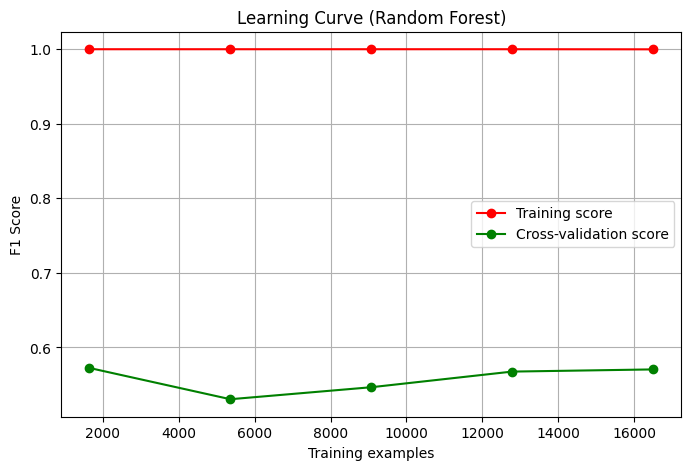

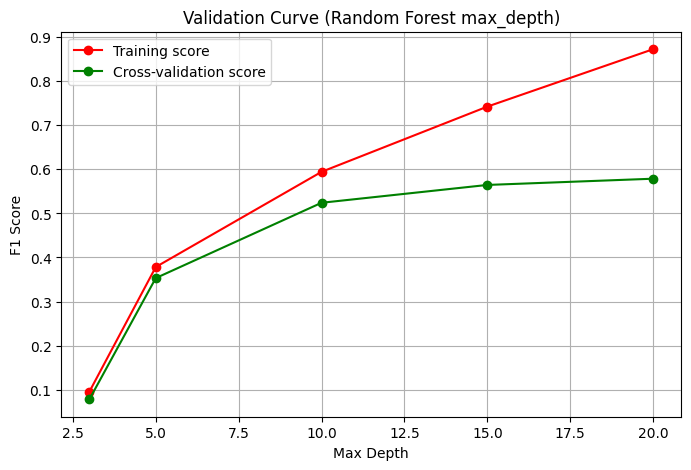

In [ ]:
from sklearn.model_selection import learning_curve, validation_curve

# 1. Learning Curve
train_sizes, train_scores, test_scores = learning_curve(
    grid_search.best_estimator_, X_train, y_train, cv=tscv, n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 5), scoring='f1')

train_scores_mean = np.mean(train_scores, axis=1)
test_scores_mean = np.mean(test_scores, axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_scores_mean, 'o-', color="r", label="Training score")
plt.plot(train_sizes, test_scores_mean, 'o-', color="g", label="Cross-validation score")
plt.title("Learning Curve (Random Forest)")
plt.xlabel("Training examples")
plt.ylabel("F1 Score")
plt.legend(loc="best")
plt.grid(True)
plt.savefig('/content/drive/MyDrive/CSC4110_G07/outputs/learning_curve.png')
plt.show()

# 2. Validation Curve (Tuning max_depth)
param_range = [3, 5, 10, 15, 20]
train_scores, test_scores = validation_curve(
    grid_search.best_estimator_, X_train, y_train, param_name="classifier__max_depth",
    param_range=param_range, cv=tscv, scoring='f1', n_jobs=-1)

train_scores_mean = np.mean(train_scores, axis=1)
test_scores_mean = np.mean(test_scores, axis=1)

plt.figure(figsize=(8, 5))
plt.plot(param_range, train_scores_mean, 'o-', color="r", label="Training score")
plt.plot(param_range, test_scores_mean, 'o-', color="g", label="Cross-validation score")
plt.title("Validation Curve (Random Forest max_depth)")
plt.xlabel("Max Depth")
plt.ylabel("F1 Score")
plt.legend(loc="best")
plt.grid(True)
plt.savefig('/content/drive/MyDrive/CSC4110_G07/outputs/validation_curve.png')
plt.show()

This cell generates the Learning Curve and Validation Curve to diagnose whether the model is underfitting or overfitting.

Learning Curve: Plots the training and cross-validation F1 scores as the amount of training data increases. This shows how the model's performance changes with more data (and whether it has high variance).

Validation Curve: Plots the training and cross-validation F1 scores against different values of a specific hyperparameter (max_depth). This helps us visually see the point where the model starts to overfit (where the training score stays high but the validation score drops).

Output: Saves both charts to the outputs folder for the report.



In [12]:
# Get probabilities from the best model
y_probs = grid_search.predict_proba(X_test)[:, 1]

# 1. Default Threshold (0.5)
y_pred_05 = (y_probs >= 0.5).astype(int)
report_05 = classification_report(y_test, y_pred_05, output_dict=True)

# 2. Lowered Threshold (0.3)
y_pred_03 = (y_probs >= 0.3).astype(int)
report_03 = classification_report(y_test, y_pred_03, output_dict=True)

# Store results in threshold_results
threshold_results = {
    'Threshold 0.5': {
        'Precision': report_05['1']['precision'],
        'Recall': report_05['1']['recall'],
        'F1-Score': report_05['1']['f1-score']
    },
    'Threshold 0.3': {
        'Precision': report_03['1']['precision'],
        'Recall': report_03['1']['recall'],
        'F1-Score': report_03['1']['f1-score']
    }
}

print(pd.DataFrame(threshold_results).T)

               Precision    Recall  F1-Score
Threshold 0.5   0.756761  0.469564  0.579533
Threshold 0.3   0.583377  0.702314  0.637344


This cell performs the Exam Skill task: evaluating how changing the decision threshold impacts the model's performance.

Get Probabilities: Extracts the predicted probability of rain from the best model.

Threshold 0.5: Uses the default threshold to predict rain only if the probability is 50% or higher, generating a classification report.

Threshold 0.3: Lowers the threshold to predict rain if the probability is 30% or higher, generating a second classification report.

Comparison Table: Combines the Precision, Recall, and F1-Score for both thresholds into a single DataFrame called threshold_results to clearly show the trade-off.